In [16]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.width", 220, "display.max_columns", 80)

DATASET_BASE_DIR = Path("/home/ethantu/workspace/good-vibrations/experiments")
BOX_DIRS = {
    "gastro":    DATASET_BASE_DIR / "2026_09_27_gastronorm_four_objs",
    "cardboard": DATASET_BASE_DIR / "2026_10_11_cardboard_four_objs",
    "plastic":   DATASET_BASE_DIR / "2026_10_05_green_plastic_four_objs",
}
FFT_NAMES = ["vibration/04_ffts.npz", "vibration/04_fft.npz"]  # FFT filename differs across boxes; first one that exists wins
SHIFT_NAMES = ["vibration/02_raw_shifts.npy", "vibration/02_raw_shift.npy"]  # raw per-laser shifts; all 3 four_objs use 02_raw_shifts.npy

# one row per sample dir (metadata + FFT path only, no arrays loaded)
#   sample-id = sample dir name (gastro '000005', speaker in metadata; plastic/cardboard '003572-1' = position-speaker)
#   speaker   = metadata 'speaker'
#   object    = metadata 'objects' keys, sorted, joined with '+' ('empty' if none)
#   layout    = metadata 'layout' (the arrangement/session name, e.g. 'vase-grid-1', 'empty-box-1')
#   com_x/y   = metadata 'avg_com', which is (row, col) in 02_cropped_overhead pixels (== 03_smask centroid; mean of
#               per-object 'coms' when there are several). Convention here: com_x = column, com_y = row. NaN for empty boxes.
#   fft_path  = vibration/04_ffts.npz (or 04_fft.npz): fft (1, L=100, F=1170, xy=2) complex64, freqs (F,) Hz 100-1000, n_samples
#   shift_path = vibration/02_raw_shifts.npy: (L=100, T=3250, xy=2) float32, T at metadata fps=2500 -> 1.3 s
rows = []
for box, exp_dir in BOX_DIRS.items():
    for d in sorted((exp_dir / "samples").iterdir()):
        if not (d / "metadata.jsonl").exists(): continue
        m = {}
        for line in (d / "metadata.jsonl").read_text().splitlines():
            if line.strip(): m.update(json.loads(line))
        com = m.get("avg_com")
        if isinstance(com, str): com = [float(v) for v in com.strip("[]").replace(",", " ").split()]  # old numpy-repr strings
        com = com if com is not None and len(com) == 2 and min(com) >= 0 else [np.nan, np.nan]
        objs = sorted(m.get("objects") or {})
        rows.append({
            "box": box,
            "sample-id": d.name,
            "speaker": int(m["speaker"]),
            "object": "+".join(objs) if objs else "empty",
            "layout": m.get("layout"),
            "com_x": float(com[1]),
            "com_y": float(com[0]),
            "fft_path": next((str(d / n) for n in FFT_NAMES if (d / n).exists()), None),
            "shift_path": next((str(d / n) for n in SHIFT_NAMES if (d / n).exists()), None),
        })
df = pd.DataFrame(rows, columns=["box", "sample-id", "speaker", "object", "layout", "com_x", "com_y", "fft_path", "shift_path"])

print(f"{len(df)} samples")
print(df.groupby("box", sort=False).agg(n=("sample-id", "size"), empty=("object", lambda s: (s == "empty").sum()),
                                        no_com=("com_x", lambda s: s.isna().sum()), no_fft=("fft_path", lambda s: s.isna().sum()),
                                        no_shift=("shift_path", lambda s: s.isna().sum()),
                                        speakers=("speaker", lambda s: sorted(s.unique().tolist()))))
df.head()

19119 samples
              n  empty  no_com  no_fft  no_shift         speakers
box                                                              
gastro     6155     60      60       0         0  [1, 2, 3, 4, 7]
cardboard  7228     88      88       0         0  [1, 3, 4, 5, 7]
plastic    5736     60      60       0         0  [1, 3, 4, 5, 7]


,box,sample-id,speaker,object,layout,com_x,com_y,fft_path,shift_path
0,gastro,000005,1,empty,empty-box-1,NaN,NaN,/home/ethantu/workspace/good-vibrations/experi...,/home/ethantu/workspace/good-vibrations/experi...
1,gastro,000006,2,empty,empty-box-1,NaN,NaN,/home/ethantu/workspace/good-vibrations/experi...,/home/ethantu/workspace/good-vibrations/experi...
2,gastro,000007,3,empty,empty-box-1,NaN,NaN,/home/ethantu/workspace/good-vibrations/experi...,/home/ethantu/workspace/good-vibrations/experi...
3,gastro,000008,4,empty,empty-box-1,NaN,NaN,/home/ethantu/workspace/good-vibrations/experi...,/home/ethantu/workspace/good-vibrations/experi...
4,gastro,000009,7,empty,empty-box-1,NaN,NaN,/home/ethantu/workspace/good-vibrations/experi...,/home/ethantu/workspace/good-vibrations/experi...


In [17]:
# pick one sample: filter by box, then by sample-id (gastro: '000005'; plastic/cardboard: '003572-1')
BOX = "cardboard"
SAMPLE_ID = "003572-1"
row = df[(df["box"] == BOX) & (df["sample-id"] == SAMPLE_ID)].iloc[0]
SAMPLE_DIR = str(Path(row["fft_path"]).parent.parent)
SAMPLE_DIR

'/home/ethantu/workspace/good-vibrations/experiments/2026_10_11_cardboard_four_objs/samples/003572-1'

In [26]:
import os

import matplotlib.pyplot as plt

FPS = 2500  # camera fps, same for all 3 boxes (metadata 'fps')

def plot_sample(df, sample_id, kind="fft", box=None, laser=None, save_dir=None, axis_lw=3, axis="box"):
    """kind='fft': |FFT| vs Hz, kind='shift': raw shift (px) vs s. One figure for x, then one for y.
    laser=None: laser x freq/time heatmap; laser=i: line plot of that laser"""
    r = df[(df["sample-id"] == sample_id) & ((df["box"] == box) if box else True)]
    assert len(r) == 1, f"{len(r)} rows for sample-id={sample_id!r} box={box!r}: pass box= to disambiguate"
    r = r.iloc[0]
    if kind == "fft":
        z = np.load(r.fft_path)
        a, t, xlabel, ylabel = np.abs(z["fft"][0]), z["freqs"], "frequency (Hz)", "|FFT|"  # (L, F, 2)
    else:
        a = np.load(r.shift_path)                                                           # (L, T, 2)
        t, xlabel, ylabel = np.arange(a.shape[1]) / FPS, "time (s)", "shift (px)"
    if laser is not None: assert 0 <= laser < a.shape[0], f"laser={laser} out of range [0, {a.shape[0]})"
    title = f"{r['box']} / {r['sample-id']} / {r['object']} / speaker {r['speaker']} / {r['layout']}"

    for i, (c, col) in enumerate([("x", "tab:blue"), ("y", "tab:orange")]):
        fig = plt.figure(figsize=(10, 4))
        plt.plot(t, a[laser, :, i], color=col, lw=1.0)
        plt.xlim(t[0], t[-1])
        plt.xticks([])
        plt.yticks([])
        ax = plt.gca()
        for sp in ax.spines.values(): sp.set_linewidth(axis_lw)  # thick axis lines so they read in the figure
        if axis == "xy":  # L-shaped x/y axes instead of a full box
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
        plt.tight_layout()
        if save_dir is not None:
            os.makedirs(save_dir, exist_ok=True)
            fig.savefig(f"{save_dir}/{r['box']}_{sample_id}_{kind}_{'all' if laser is None else laser}_{c}_{axis}.svg", bbox_inches="tight")
        plt.show()

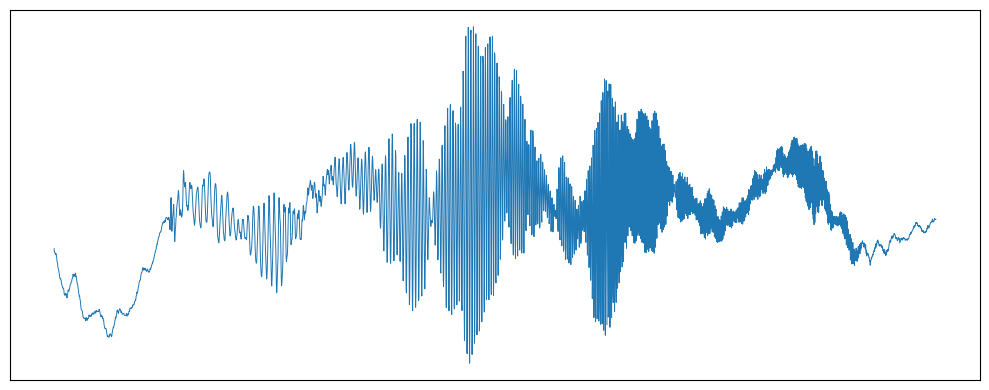

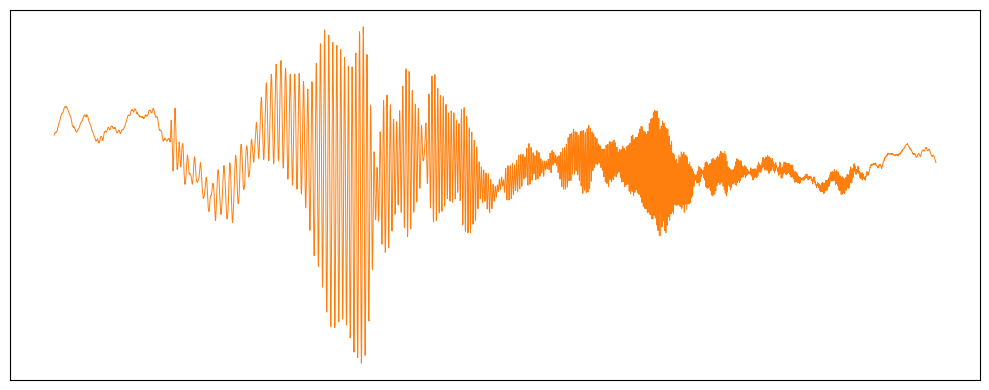

In [27]:
plot_sample(df, SAMPLE_ID, "shift", box=BOX, laser=0, save_dir="plots")

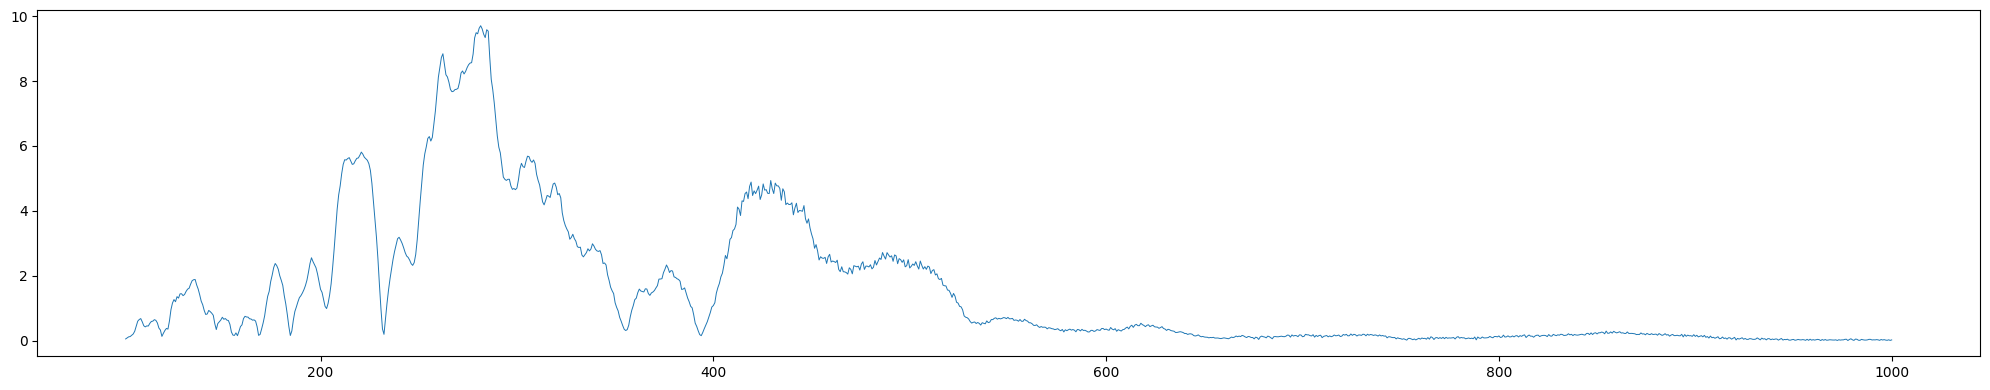

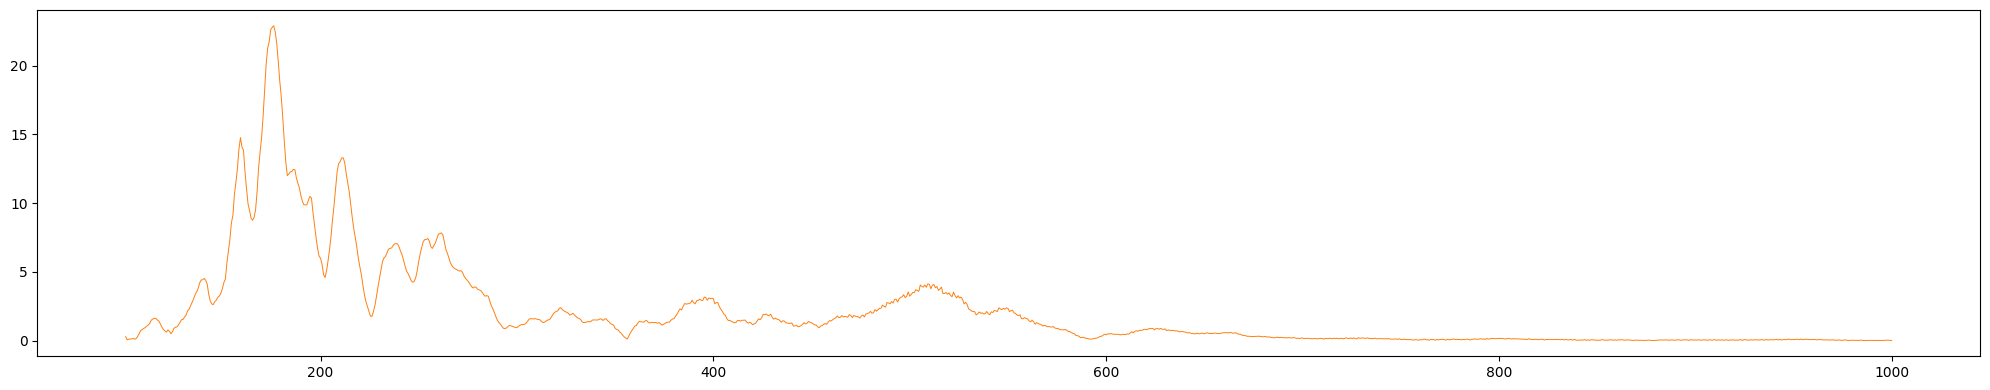

In [20]:
plot_sample(df, SAMPLE_ID, "fft", box=BOX, laser=0)